# C03-KM — KMeans trên RFM + AOV + Diversity + Tenure (log1p + Standard + PCA 90%)

Thí nghiệm **C03-KM** (người chạy: An) theo chiến lược model. So với C01, **thêm Tenure** (observed_span_days — số ngày từ đơn đầu tiên đến đơn cuối cùng, đo độ dài quan hệ với khách hàng). Nhánh C03 tách từ C01, không cộng dồn với C02 (QtyPerOrder).

## Params

In [1]:
FEATURES_C01 = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
FEATURES = FEATURES_C01 + ["Tenure"]     # C03: thêm Tenure (Tenure = ngày cuối - ngày đầu)
K_GRID = range(2, 11)
RANDOM_STATE = 42
N_INIT = 20
PCA_VAR = 0.90

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={
    "avg_order_value": "AOV", "n_stock_codes": "Diversity",
    "avg_quantity_per_order": "QtyPerOrder", "observed_span_days": "Tenure"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
print("Số khách Tenure = 0 (chỉ mua đúng 1 ngày):", int((X["Tenure"] == 0).sum()))
X.describe().round(2)

Dữ liệu đầu vào: (4327, 6)
Số khách Tenure = 0 (chỉ mua đúng 1 ngày): 1506


,Recency,Frequency,Monetary,AOV,Diversity,Tenure
count,4327.00,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49,130.59
std,99.98,7.64,8441.89,466.49,85.31,132.24
min,1.00,1.00,2.90,2.90,1.00,0.00
25%,18.00,1.00,301.52,175.47,16.00,0.00
50%,51.00,2.00,657.90,286.70,35.00,92.14
75%,143.00,5.00,1624.10,421.99,77.00,252.03
max,374.00,206.00,278748.02,14844.77,1784.00,373.10


**Nhận xét:** 4.327 khách, 6 feature. 1.506 khách (34,8%) có Tenure = 0 (chỉ mua trong đúng 1 ngày — không nhất thiết là mua 1 đơn, vì Frequency tính theo số hóa đơn có thể >1 nếu cùng ngày). `log1p(0)=0` nên không cần xử lý riêng.

## log1p, chuẩn hóa, PCA giữ 90% phương sai

In [3]:
X_scaled = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X)
ev = PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_
cum = np.cumsum(ev)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)
print(pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew()}).round(2))
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")

           skew_raw  skew_log1p
Recency        1.25       -0.33
Frequency     11.95        1.21
Monetary      21.04        0.35
AOV           11.94       -0.00
Diversity      6.92       -0.24
Tenure         0.46       -0.39
Phương sai tích lũy: [0.6149 0.8008 0.8934 0.9592 0.9999 1.    ]
Số PC giữ lại: 4 / 6 (phương sai giữ 95.92%)


**Nhận xét:** Tenure có skew gốc chỉ 0,46 (thấp nhất trong 6 biến, vì không lệch phải kiểu Monetary) nên log1p chỉ chỉnh nhẹ (-0,39). PCA 90% cần **4/6 PC** (giữ 95,92%) — nhiều hơn C01 (3 PC) và C02 (3 PC), vì Tenure mang thông tin khá độc lập với RFM (khác AOV/QtyPerOrder, vốn gần phụ thuộc Frequency-Monetary).

## Quét số cụm k

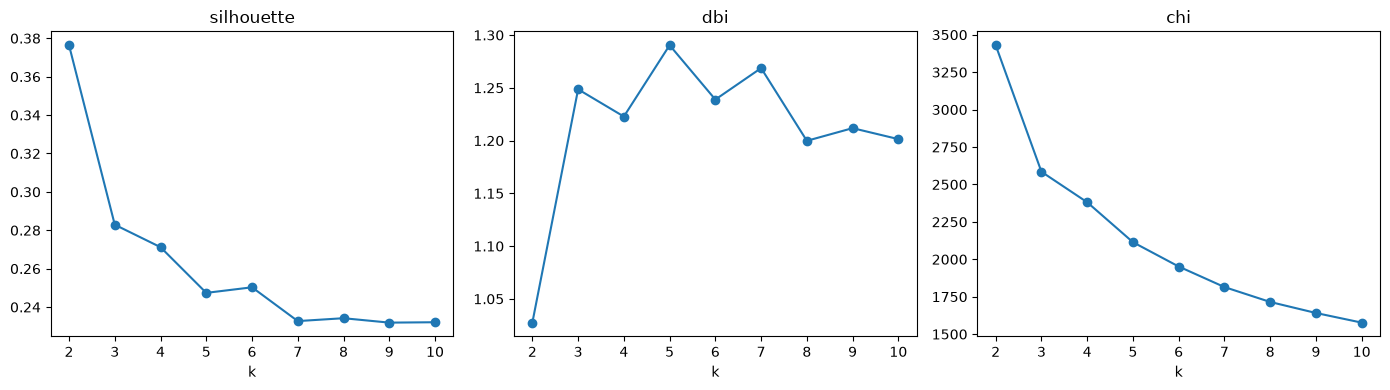

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.3764,1.0275,3430.3,13887.6,2142
1,3,0.2829,1.2486,2584.9,11341.9,1160
2,4,0.2712,1.2228,2381.1,9388.7,817
3,5,0.2474,1.2904,2114.3,8422.2,712
4,6,0.2503,1.2389,1951.8,7642.4,449
5,7,0.2327,1.2687,1814.6,7074.1,302
6,8,0.2342,1.1998,1715.0,6588.7,270
7,9,0.2319,1.2118,1641.4,6162.3,270
8,10,0.2321,1.2014,1577.0,5807.9,136


In [4]:
rows = []
for k in K_GRID:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
    rows.append({"k": k, "silhouette": round(silhouette_score(Z, km.labels_), 4),
                 "dbi": round(davies_bouldin_score(Z, km.labels_), 4),
                 "chi": round(calinski_harabasz_score(Z, km.labels_), 1),
                 "inertia": round(km.inertia_, 1),
                 "min_cluster": int(np.bincount(km.labels_).min())})
metrics = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "chi"]):
    ax.plot(metrics["k"], metrics[col], marker="o")
    ax.set_xlabel("k"); ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG / "kmeans_metrics_by_k.png", dpi=150); plt.show()
metrics

**Nhận xét:** Silhouette cao nhất ở k=2 (0,3764), giảm dần theo k — giống mẫu đã thấy ở B03-KM (k=2 là nghiệm tốt nhất theo quy tắc, không phải tách ngoại lai).

## Chọn k và huấn luyện mô hình cuối

In [5]:
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("k được chọn (Silhouette lớn nhất):", best_k)

model = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler()),
                   ("pca", PCA(n_components=n_pc, svd_solver="full")),
                   ("kmeans", KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT))]).fit(X)
labels = model["kmeans"].labels_
assert (model[:-1].transform(X) == Z).all()
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))

k được chọn (Silhouette lớn nhất): 2
0    2185
1    2142
Name: Số khách, dtype: int64


**Nhận xét:** k=2 chia **2.185 và 2.142 khách (50,5% / 49,5%)** — cân đối gần như tuyệt đối, tốt hơn cả B03-KM (46,2%/53,8%).

## Đối chiếu C01 (bằng KMeans) và B03-KM

Dựng lại C01 bằng KMeans (bớt Tenure) để so trực tiếp; so thêm với B03-KM (RFM + Yeo–Johnson, không feature hành vi).

In [6]:
X_c01 = X[FEATURES_C01]
Xs_c01 = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X_c01)
cum_c01 = np.cumsum(PCA(svd_solver="full").fit(Xs_c01).explained_variance_ratio_)
n_pc_c01 = int(np.searchsorted(cum_c01, PCA_VAR) + 1)
Z_c01 = PCA(n_components=n_pc_c01, svd_solver="full").fit_transform(Xs_c01)
labels_c01 = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(Z_c01)

print("Số PC: C03 =", Z.shape[1], "| C01 (KMeans, dựng lại) =", Z_c01.shape[1])
print("ARI (C03-KM vs C01 bằng KMeans, k cố định =", best_k, "):", round(adjusted_rand_score(labels, labels_c01), 4))

from sklearn.preprocessing import PowerTransformer
X_rfm = df[["Recency", "Frequency", "Monetary"]]
Z_b03 = PCA(n_components=0.90, svd_solver="full").fit_transform(
    StandardScaler().fit_transform(PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(X_rfm)))
labels_b03 = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(Z_b03)
print("ARI (C03-KM vs B03-KM, k cố định =", best_k, "):", round(adjusted_rand_score(labels, labels_b03), 4))

Số PC: C03 = 4 | C01 (KMeans, dựng lại) = 3
ARI (C03-KM vs C01 bằng KMeans, k cố định = 2 ): 0.6493
ARI (C03-KM vs B03-KM, k cố định = 2 ): 0.7292


**Nhận xét:** ARI so với C01 (KMeans) = 0,6493 — khác biệt rõ, Tenure đổi cách chia nhóm thật sự. ARI so với **B03-KM** (RFM + Yeo-Johnson, không feature hành vi) = **0,7292** — khá giống nhau, cả hai pipeline độc lập đều hội tụ về cùng một ranh giới khách giá trị cao/thấp.

## Hồ sơ cụm

In [7]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"),
    Tenure=("Tenure", "median"), Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,Tenure,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,
0,2185,24.0,4.0,1561.6,337.9,74.0,245.0,50.5,90.6
1,2142,121.0,1.0,301.5,213.7,17.0,0.0,49.5,9.4


**Nhận xét:** Cụm 0 (2.185 khách, 50,5%) mua gần đây, thường xuyên, Tenure dài (Recency 24, Frequency 4, Tenure 245 ngày) — chiếm **90,6% Monetary**. Cụm 1 (2.142 khách, 49,5%) mua 1 lần, Tenure=0, Recency 121 — chỉ 9,4% Monetary. Ranh giới giá trị rõ hơn cả B03-KM (88,2%/11,8%), và có thêm chiều Tenure giải thích rõ lý do: cụm giá trị cao là khách có quan hệ mua hàng kéo dài, không phải chỉ mua nhiều tiền một lần.

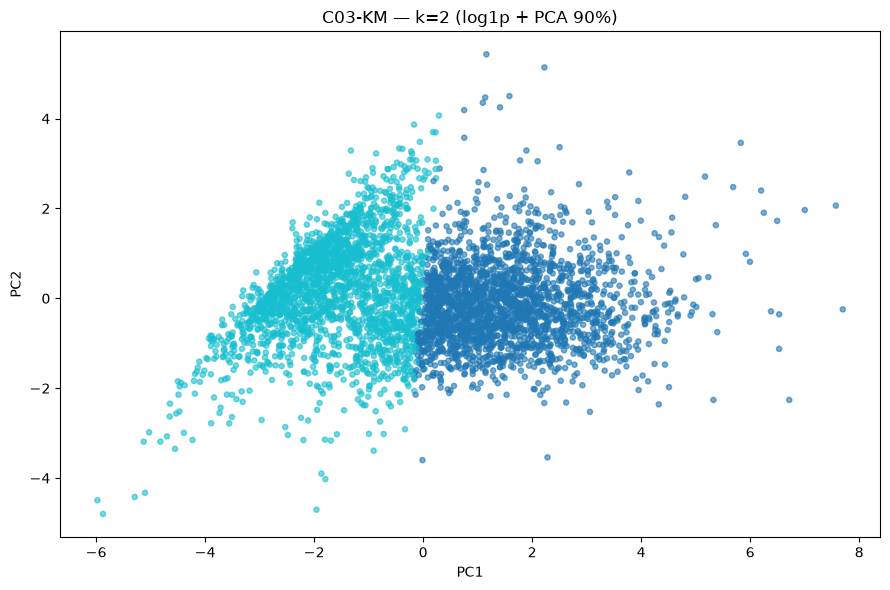

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=14, alpha=0.6)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"C03-KM — k={best_k} (log1p + PCA 90%)")
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Hai cụm tách thành hai khối rõ rệt, giống B03-KM — xác nhận feature hành vi (ở đây là Tenure) khi kết hợp đúng cách (log1p + chuẩn hóa) vẫn giữ được cấu trúc phân khúc cân đối.

## Lưu kết quả

In [9]:
metrics.to_csv(OUT / "kmeans_c03_metrics_by_k.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_c03_labels.csv", index=False)
joblib.dump(model, "kmeans_c03_model.pkl")
params = {"experiment": "C03-KM", "features": FEATURES,
          "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes", "Tenure": "observed_span_days"},
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "k": best_k, "silhouette": float(metrics.loc[metrics.k == best_k, "silhouette"].iloc[0]),
          "dbi": float(metrics.loc[metrics.k == best_k, "dbi"].iloc[0]),
          "chi": float(metrics.loc[metrics.k == best_k, "chi"].iloc[0]),
          "ari_vs_c01_km": float(adjusted_rand_score(labels, labels_c01)),
          "ari_vs_b03_km": float(adjusted_rand_score(labels, labels_b03))}
json.dump(params, open(OUT / "kmeans_c03_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['kmeans_c03_labels.csv', 'kmeans_c03_metrics_by_k.csv', 'kmeans_c03_params.json']


**Nhận xét kết luận C03-KM:** Đây là kết quả cân đối và rõ ràng nhất trong toàn bộ dự án tính đến nay — 50,5%/49,5% khách, ranh giới Monetary 90,6%/9,4%, và ARI=0,73 so với B03-KM cho thấy hai pipeline khác nhau (RFM+Yeo-Johnson so với RFM+AOV+Diversity+Tenure) đều hội tụ về cùng kết luận: khách hàng giá trị cao là nhóm mua thường xuyên, gần đây, và có quan hệ mua hàng kéo dài (Tenure cao). Đề xuất B03-KM hoặc C03-KM làm mô hình chính cho phần dự đoán khách hàng giá trị cao của đồ án.